### SciPy
It is open-source Python library used for scientific and technical computing

**Installation Command:** pip install scipy

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as st

### Discrete Distributions

#### 1. Bernoulli Distribution

In [2]:
from scipy.stats import bernoulli

In [3]:
# probability of success
p = 0.8

In [4]:
p_success = bernoulli.pmf(1,p)
p_failure = bernoulli.pmf(0,p)

In [5]:
print('Probability of Success:',p_success)
print('Probability of Failure:',p_failure)

Probability of Success: 0.8
Probability of Failure: 0.2


#### 2. Binomial Distribution

In [6]:
from scipy.stats import binom

In [17]:
n = 10       # number of trials
p = 0.6      # prob of success
outcome = 4  # number of events

In [18]:
# PMF of 5 successes in 10 trials
pmf = binom.pmf(outcome, n, p)
print('PMF:',pmf)

PMF: 0.11147673600000006


In [19]:
# CDF of 4 or less than 4 successes in 10 trials
cdf = binom.cdf(outcome, n, p)
print('CDF:',cdf)

CDF: 0.16623861760000014


#### 3. Poisson Distribution

In [21]:
from scipy.stats import poisson

In [22]:
avg_lambda = 3            # avg event rate
outcome = 2               # number of events

In [23]:
# PMF for exactly 2 events with a mean rate of 3
pmf = poisson.pmf(outcome, avg_lambda)
print('PMF:',pmf)

PMF: 0.22404180765538775


In [24]:
# CDF for 2 or fewer events with a mean rate of 3
cdf = poisson.cdf(outcome, avg_lambda)
print('CDF:',cdf)

CDF: 0.42319008112684364


#### 4. Multinomial Distribution

In [25]:
from scipy.stats import multinomial

In [27]:
n = 10                           # number of trials
prob = [0.6, 0.3, 0.1]           # probabilities of events
outcomes = [5, 3, 2]             # number of events

In [28]:
# PMF for a specific outcome set
pmf = multinomial.pmf(outcomes, n, prob)
print('PMF:',pmf)

PMF: 0.052907904000000054


<hr>

### Plot Shapes of Binomial Distribution:

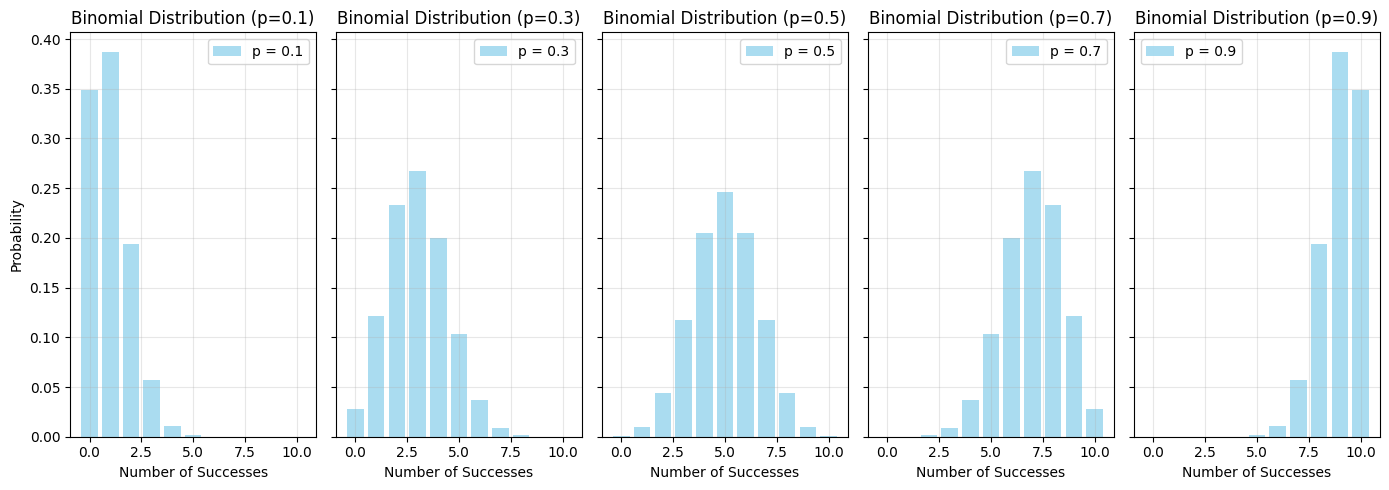

In [29]:
# Parameters
n = 10                                    # Fixed number of trials
p_values = [0.1, 0.3, 0.5, 0.7, 0.9]      # Different probabilities of success
x = np.arange(0, n + 1)                   # Possible outcomes (0 to n)

# Create subplots
fig, axes = plt.subplots(1, len(p_values), figsize=(14, 5), sharey=True)

for i, p in enumerate(p_values):
    # Calculate PMF for each probability of success
    pmf = binom.pmf(x, n, p)

    # Plot
    axes[i].bar(x, pmf, color='skyblue', alpha=0.7, label=f'p = {p}')
    axes[i].set_title(f'Binomial Distribution (p={p})', fontsize=12)
    axes[i].set_xlabel('Number of Successes', fontsize=10)
    axes[i].set_ylabel('Probability' if i == 0 else '', fontsize=10)
    axes[i].legend()
    axes[i].grid(alpha=0.3)

# Adjust layout
plt.tight_layout()
plt.show()

#### Tips Dataset:
It is a restaurant billing data that contains information about customers in a restaurant and how much tip they gave based on different factors.

In [30]:
import seaborn as sns

# Loading the tips dataset
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [35]:
tips.shape

(244, 7)

#### Questions:
1. What is the proportion of smokers among male and female customers?

In [33]:
# Group data by sex and smoker
grouped_smoker_data = tips.groupby('sex')['smoker'].value_counts(normalize=True).unstack()
grouped_smoker_data

C:\Users\Maisara Waseem\AppData\Local\Temp\ipykernel_35548\509609579.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_smoker_data = tips.groupby('sex')['smoker'].value_counts(normalize=True).unstack()


smoker,Yes,No
sex,,
Male,0.382166,0.617834
Female,0.379310,0.620690


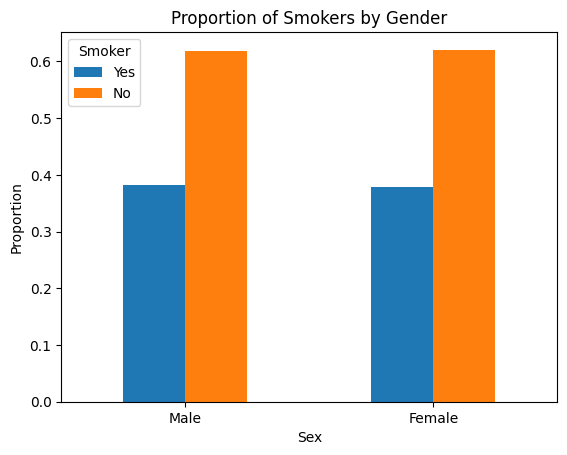

In [61]:
# Visualizing using a bar chart

grouped_smoker_data.plot(kind='bar')
plt.title('Proportion of Smokers by Gender')
plt.xlabel('Sex')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.legend(title='Smoker')
plt.show()

**Observation:**

- Female customers: 37.9% are smokers, while 62% are non-smokers
- Male customers: 38.2% are smokers, while 61.7% are non-smokers

2. What is the expected number of smokers among male and female customers?

This question uses the binomial distribution to calculate the mean or expected number of smokers for male and female groups.<br>The mean (μ) is given by:   μ=n⋅p

In [34]:
# Total customers for each gender
grouped_smoker_data['Total_Customers'] = tips.groupby('sex')['smoker'].count()
grouped_smoker_data

C:\Users\Maisara Waseem\AppData\Local\Temp\ipykernel_35548\1388847225.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_smoker_data['Total_Customers'] = tips.groupby('sex')['smoker'].count()


smoker,Yes,No,Total_Customers
sex,,,
Male,0.382166,0.617834,157
Female,0.379310,0.620690,87


In [38]:
# Calculate expected number of smokers (Mean) - n*p
grouped_smoker_data['Expected_Smokers'] = grouped_smoker_data['Total_Customers'] * grouped_smoker_data['Yes']
grouped_smoker_data

smoker,Yes,No,Total_Customers,Expected_Smokers
sex,,,,
Male,0.382166,0.617834,157,60.0
Female,0.379310,0.620690,87,33.0


- There are ~ 60 expected males who smoke
- There are ~ 33 expected females who smoke

3. What is the variability (standard deviation) in the number of smokers within male and female groups?

For a binomial distribution:

Standard deviation -
$\sigma = \sqrt{n \cdot p \cdot (1-p)}$

In [39]:
grouped_smoker_data['Std_Deviation'] = np.sqrt(grouped_smoker_data['Expected_Smokers'] * (1 - grouped_smoker_data['Yes']))
grouped_smoker_data

smoker,Yes,No,Total_Customers,Expected_Smokers,Std_Deviation
sex,,,,,
Male,0.382166,0.617834,157,60.0,6.088519
Female,0.379310,0.620690,87,33.0,4.525788


4. What is the probability of observing exactly 50 smokers among male and female customers?

The PMF (Probability Mass Function) of the binomial distribution can compute the likelihood of seeing a specific count of smokers (e.g., exactly 50 smokers).

In [40]:
num_events = 50

# PMF for exactly 50 smokers in each gender
grouped_smoker_data['PMF_50_Smokers'] = grouped_smoker_data.apply(lambda row: binom.pmf(num_events, row['Total_Customers'], row['Yes']), axis=1)
grouped_smoker_data

smoker,Yes,No,Total_Customers,Expected_Smokers,Std_Deviation,PMF_50_Smokers
sex,,,,,,
Male,0.382166,0.617834,157,60.0,6.088519,0.017117
Female,0.379310,0.620690,87,33.0,4.525788,0.000097


5. How can we visualize the binomial probability distribution for smokers among males and females?

In [45]:
# grouped_smoker_data.index

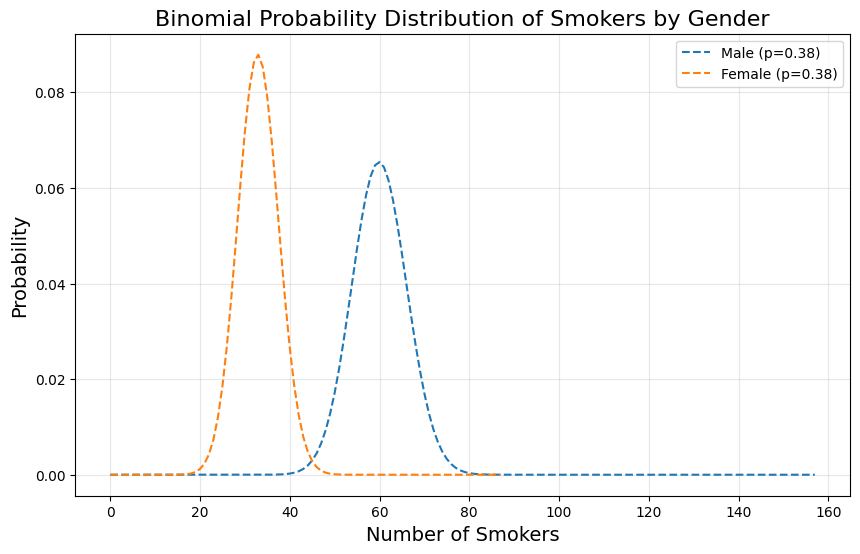

In [47]:
plt.figure(figsize=(10, 6))

for s in grouped_smoker_data.index:
    n = grouped_smoker_data.loc[s, 'Total_Customers']
    p_smoker = grouped_smoker_data.loc[s, 'Yes']
    x = np.arange(0, n+1)
    binomial_pmf = binom.pmf(x, n, p_smoker)
    plt.plot(x, binomial_pmf, label=f"{s} (p={p_smoker:.2f})", linestyle = '--')

plt.title("Binomial Probability Distribution of Smokers by Gender", fontsize=16)
plt.xlabel("Number of Smokers", fontsize=14)
plt.ylabel("Probability", fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **Plot Shapes of Poisson Distribution::**

λ = average number of events<br>
k = Possible number of events → 0, 1, 2, ..., 19

**How many times can the event occur?**

In [48]:
from scipy.stats import poisson

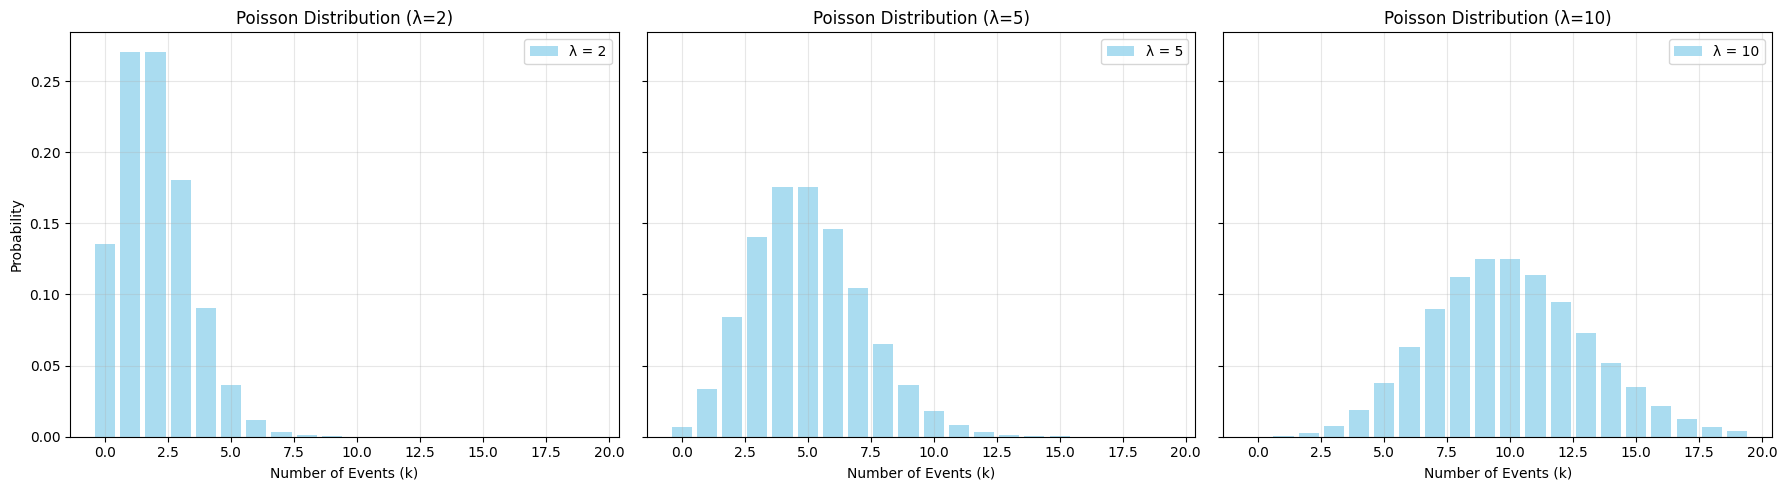

In [49]:
# Parameters
lambda_values = [2, 5, 10]        # Different average rates (lambda)
k = np.arange(0, 20)              # Possible values of events (0 to 19)

# Create subplots
fig, axes = plt.subplots(1, len(lambda_values), figsize=(18, 5), sharey=True)    # sharey=True means all graphs share same Y-axis

for i, lambda_val in enumerate(lambda_values):
    # Calculate PMF for each lambda value
    pmf = poisson.pmf(k, lambda_val)

    # Plot
    axes[i].bar(k, pmf, color='skyblue', alpha=0.7, label=f'λ = {lambda_val}')
    axes[i].set_title(f'Poisson Distribution (λ={lambda_val})', fontsize=12)
    axes[i].set_xlabel('Number of Events (k)', fontsize=10)
    axes[i].set_ylabel('Probability' if i == 0 else '', fontsize=10)
    axes[i].legend()
    axes[i].grid(alpha=0.3)

# Adjust layout so graphs don’t overlap
plt.tight_layout()
plt.show()

λ=2 : Most of the probability is concentrated near 0, and the distribution is heavily skewed to the right.

λ=5 : The peak shifts to around 5, with a more spread-out curve

λ=10 : The distribution becomes symmetric, centered at 10.

#### Example: Poisson Distribution in Call Center Data

For this we create a dataset that typically contain:
- Time intervals: Minutes or hours during which calls are recorded.
- Number of calls: Count of calls received in each interval.

In [50]:
from scipy.stats import poisson

In [51]:
# Average rate of calls per interval (lambda)
lambda_values = [2, 5, 10]  # Different average rates for analysis
intervals = 100             # Number of intervals to simulate

Random samples are generated using poisson.rvs() for different values of  λ  (average rate of calls).

In [52]:
call_data = {f"λ={lambda_val}": poisson.rvs(lambda_val, size=intervals) for lambda_val in lambda_values}
call_data

{'λ=2': array([4, 3, 0, 2, 1, 0, 2, 5, 2, 2, 2, 0, 2, 3, 1, 0, 3, 1, 2, 1, 0, 2,
        0, 2, 0, 1, 1, 1, 1, 3, 3, 2, 0, 2, 1, 1, 2, 3, 1, 1, 4, 0, 0, 4,
        3, 3, 2, 3, 2, 1, 1, 1, 3, 1, 3, 0, 2, 1, 3, 2, 2, 0, 3, 2, 1, 1,
        4, 2, 5, 1, 4, 2, 2, 0, 1, 3, 6, 1, 2, 5, 2, 0, 5, 0, 1, 5, 3, 2,
        2, 5, 1, 1, 1, 0, 2, 3, 4, 1, 3, 4], dtype=int64),
 'λ=5': array([ 3,  6,  5,  1,  7,  7,  1,  4,  3,  1,  2,  1,  3,  4,  7,  1,  5,
         1,  3,  1, 10,  3,  2, 10,  7,  8,  2,  5,  2,  4,  1,  3,  4,  4,
         5,  5,  5,  3,  3,  6,  6,  3,  3,  1,  5,  6,  5,  5,  3,  3,  3,
         4, 12,  5,  3,  8,  4,  3,  3,  5,  2,  6,  8,  3,  4,  7,  4,  5,
         2, 11,  6,  2,  7,  4,  2,  9,  5,  5,  0,  6,  7,  6,  4,  5,  4,
         4,  4,  6,  5,  0,  2,  4,  9,  7,  7,  4,  5,  8,  6,  9],
       dtype=int64),
 'λ=10': array([10, 12, 10, 13, 11,  7,  5, 14, 10, 15, 11, 15,  7,  5,  8, 11, 11,
        16, 12, 11,  9, 14, 12,  9, 10, 11, 12, 14, 16, 10, 15, 15, 12,  9,
 

#### Questions
1. What is the average rate of calls ( λ ) received per interval?

In [53]:
# 1. Average rate of calls (λ)
for lambda_val, calls in call_data.items():
    avg_rate = np.mean(calls)
    print(f"Average rate of calls for {lambda_val}: {avg_rate:.2f}")

Average rate of calls for λ=2: 1.94
Average rate of calls for λ=5: 4.52
Average rate of calls for λ=10: 10.15


2. What is the probability of receiving exactly (k) calls in a given interval?

In [54]:
k = 3    # Probability of receiving exactly 3 calls
for lambda_val in lambda_values:
    pmf = poisson.pmf(k, lambda_val)
    print(f"PMF (k={k}, λ={lambda_val}): {pmf:.4f}")

PMF (k=3, λ=2): 0.1804
PMF (k=3, λ=5): 0.1404
PMF (k=3, λ=10): 0.0076


3. What is the cumulative probability of receiving up to (k) calls in a given interval?

In [55]:
for lambda_val in lambda_values:
    cdf = poisson.cdf(k, lambda_val)
    print(f"CDF (up to k={k}, λ={lambda_val}): {cdf:.4f}")

CDF (up to k=3, λ=2): 0.8571
CDF (up to k=3, λ=5): 0.2650
CDF (up to k=3, λ=10): 0.0103


4. How does the variability (standard deviation) of calls relate to the average rate ( λ )?

In [56]:
for lambda_val, calls in call_data.items():
    std_dev = np.std(calls)
    print(f"Standard deviation of calls for {lambda_val}: {std_dev:.2f}")

Standard deviation of calls for λ=2: 1.43
Standard deviation of calls for λ=5: 2.45
Standard deviation of calls for λ=10: 3.04


5. Visualize the probability distribution of calls for different values of λ?

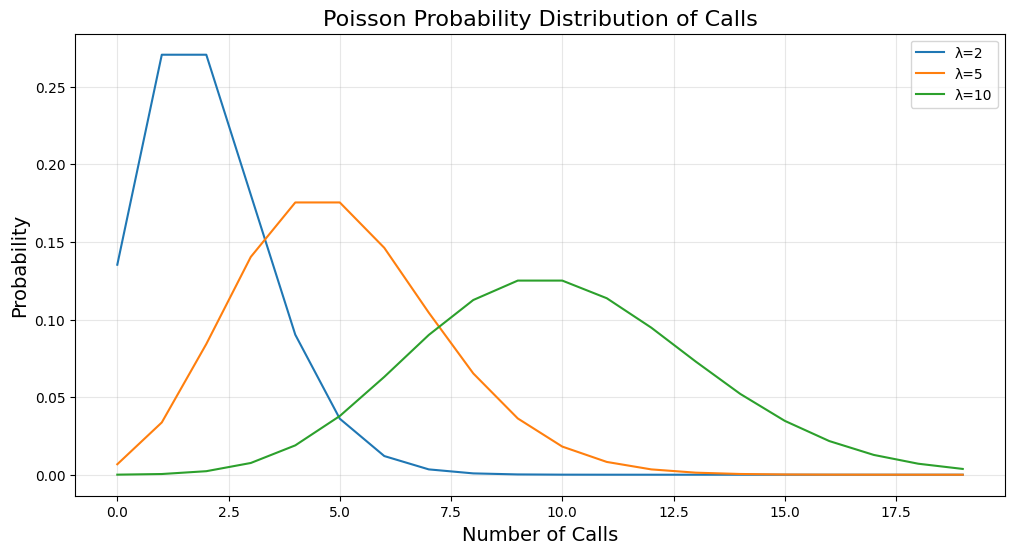

In [57]:
x = np.arange(0, 20)  # Possible number of calls (0 to 19)
plt.figure(figsize=(12, 6))
for lambda_val in lambda_values:
    pmf = poisson.pmf(x, lambda_val)
    plt.plot(x, pmf, label=f"λ={lambda_val}")

plt.title("Poisson Probability Distribution of Calls", fontsize=16)
plt.xlabel("Number of Calls", fontsize=14)
plt.ylabel("Probability", fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **Plot Shapes of Multinomial Distribution**

In [58]:
from scipy.stats import multinomial

The Tips dataset contains the day column which has more than two outcomes, it can be used for multinomial distribution.

In [59]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


#### Questions
1. What are the probabilities of customer visits on each day?

In [63]:
# Count customer visits per day
day_counts = tips['day'].value_counts()
day_counts

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

In [64]:
total_customers = day_counts.sum()
p_vals = tips['day'].value_counts(normalize=True)
p_vals

day
Sat     0.356557
Sun     0.311475
Thur    0.254098
Fri     0.077869
Name: proportion, dtype: float64

2. What is the probability of observing a specific distribution of customer visits across the days?

In [65]:
example_counts = [84, 75, 60, 25]  # Example counts for Thu, Fri, Sat, Sun
pmf_multinomial = multinomial.pmf(example_counts, total_customers, p_vals)
print("\nPMF for specific counts [84, 75, 60, 25]:")
print(f"PMF: {pmf_multinomial}")


PMF for specific counts [84, 75, 60, 25]:
PMF: 0.00012366346119658321


3. What are the expected counts and variances of customer visits for each day based on the observed probabilities?

In [66]:
expected_counts = total_customers * p_vals           # Mean counts
variances = total_customers * p_vals * (1 - p_vals)  # Variances

print("\nExpected counts per day:")
print(expected_counts)
print("\nVariances per day:")
print(variances)


Expected counts per day:
day
Sat     87.0
Sun     76.0
Thur    62.0
Fri     19.0
Name: proportion, dtype: float64

Variances per day:
day
Sat     55.979508
Sun     52.327869
Thur    46.245902
Fri     17.520492
Name: proportion, dtype: float64


4. Create a visualization of the distribution of customer visits across each day.

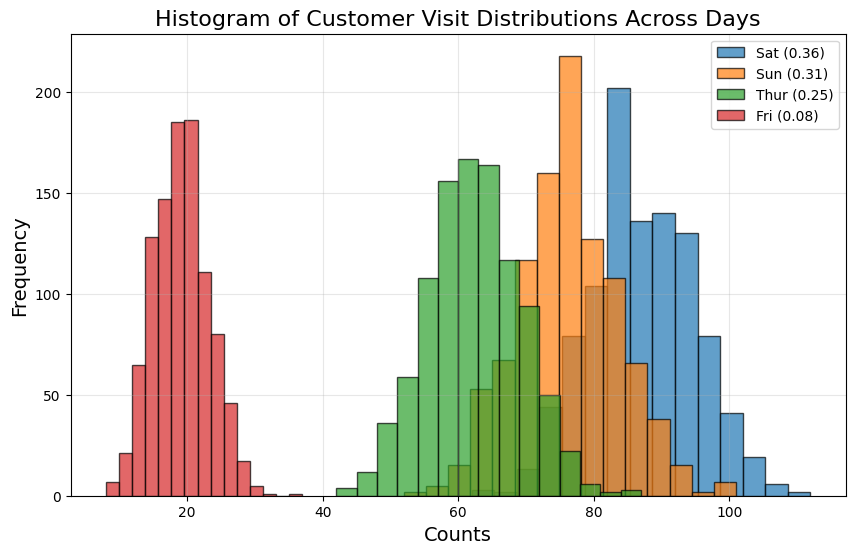

In [68]:
samples = multinomial.rvs(total_customers, p_vals, size=1000)  # Simulate data
counts_array = np.array(samples)

plt.figure(figsize=(10, 6))
for i, day in enumerate(day_counts.index):
    plt.hist(counts_array[:, i], bins=15, alpha=0.7, label=f'{day} ({p_vals[day]:.2f})', edgecolor='black')

plt.title("Histogram of Customer Visit Distributions Across Days", fontsize=16)
plt.xlabel("Counts", fontsize=14)
plt.ylabel("Frequency", fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Histograms of simulated data demonstrate how customer counts are distributed across days, reflecting observed probabilities.